# 新文章：GBD 2023与UN WPP 2024比较基准研究

以2026-10-25 SubmissionPrep_XX新稿为准，NSFG不纳入此稿。使用19国、1990—2023年、女性15—49岁的真实原始输入。

本Notebook含完整base-R分析代码，不依赖项目内其他脚本。由同版GBD人数和人口重建率，仅用UN人口替换参照18国年龄内人口份额。所有派生GBD结果为点估计，没有联合draws区间。

从项目根目录启动JupyterLab，然后依次执行所有单元。输入已存data/input；软件安装说明在README_先读我.md。

In [1]:
#!/usr/bin/env Rscript
# GBD 2023 + UN WPP 2024：可独立执行的完整核心分析，全部使用base R。
# 运行：Rscript code/PCOS_NewArticle_complete.R
# RStudio中可使用 source('code/PCOS_NewArticle_complete.R')，工作目录设为项目根目录。
# 不调用Python、不读取Python计算结果、不模拟GBD draws。

pcos_main <- function(root=NULL, output=NULL) {
  if (is.null(root)) {
    arg <- grep('^--file=',commandArgs(),value=TRUE)
    root <- if(length(arg)) dirname(dirname(normalizePath(sub('^--file=','',arg[1])))) else getwd()
  }
  input<-file.path(root,'data','input');out<-if(is.null(output)) file.path(root,'results','R') else output
  dir.create(out,recursive=TRUE,showWarnings=FALSE)
  read<-function(n) read.csv(file.path(input,n),check.names=FALSE,stringsAsFactors=FALSE)
  ages<-seq(15,45,5);years<-1990:2023
  countries<-c('Argentina','Australia','Brazil','Canada','China','France','Germany','India','Indonesia','Italy','Japan','Mexico','Republic of Korea','Russian Federation','Saudi Arabia','South Africa','Türkiye','United Kingdom','United States of America')
  refs<-sort(setdiff(countries,'China'));causes<-c('Endometriosis','Polycystic ovarian syndrome');types<-c('Primary','Secondary','Total')
  pop<-read('IHME-GBD_2023_DATA-916826fb-1.csv');pop$country<-pop$location_name;pop$age_start<-(pop$age_id-5)*5;pop$gbd_pop<-pop$val
  pop<-pop[,c('country','year','age_start','gbd_pop')]
  un<-read('UN_WPP2024_G20_female_15_49_1990_2023.csv');un$country<-un$gbd_country
  keys<-c('country','year','age_start')
  stopifnot(nrow(pop)==4522,nrow(un)==4522,!anyDuplicated(pop[keys]),!anyDuplicated(un[keys]),setequal(pop$country,countries),setequal(un$country,countries))
  pop<-merge(pop,un[,c(keys,'un_female_pop')],by=keys,all=FALSE)
  stopifnot(nrow(pop)==4522,all(pop$gbd_pop>0),all(pop$un_female_pop>0))
  w<-read('weights.csv')$weight;w<-w/sum(w);stopifnot(length(w)==7,abs(sum(w)-1)<1e-12)
  a<-read('IHME-GBD_2023_DATA-1b13e337-1.csv');a<-a[a$measure_id==5 & a$metric_id==1 & a$rei_id==198 & a$sex_id==2,];a$subtype<-'Total'
  b<-read('IHME-GBD_2023_DATA-416daf73-1.csv');b<-b[b$measure_id==5 & b$metric_id==1 & b$rei_id %in% c(220,221) & b$sex_id==2,];b$subtype<-ifelse(b$rei_id==220,'Primary','Secondary')
  keep<-c('location_name','year','age_id','cause_name','subtype','val');d<-rbind(a[,keep],b[,keep]);names(d)[names(d)=='location_name']<-'country';names(d)[names(d)=='cause_name']<-'cause';names(d)[names(d)=='val']<-'gbd_cases';d$age_start<-(d$age_id-5)*5
  stopifnot(nrow(d)==27132,!anyDuplicated(d[c(keys,'cause','subtype')]),setequal(d$cause,causes),setequal(d$subtype,types))
  cells<-merge(d[,c(keys,'cause','subtype','gbd_cases')],pop,by=keys,all=FALSE);cells$gbd_rate<-1e5*cells$gbd_cases/cells$gbd_pop
  stopifnot(nrow(cells)==27132,all(is.finite(cells$gbd_rate)),all(cells$gbd_cases>=0))
  pt<-reshape(cells[,c(keys,'cause','subtype','gbd_cases')],idvar=c(keys,'cause'),timevar='subtype',direction='wide')
  add_error<-max(abs(pt$gbd_cases.Total-pt$gbd_cases.Primary-pt$gbd_cases.Secondary));stopifnot(add_error<1e-6)
  e<-read('IHME-GBD_2023_DATA-76c5523c-1.csv');e<-e[e$measure_id==5 & e$metric_id==3 & e$sex_id==2 & e$rei_id %in% c(220,221),]
  e$country<-e$location_name;e$cause<-e$cause_name;e$age_start<-(e$age_id-5)*5;e$subtype<-ifelse(e$rei_id==220,'Primary','Secondary');e$official_rate<-e$val
  ep<-merge(e[,c(keys,'cause','subtype','official_rate')],cells,by=c(keys,'cause','subtype'));endpoint_error<-max(abs(ep$official_rate-ep$gbd_rate));stopifnot(nrow(ep)==1064,endpoint_error<1e-8)
  # 数组第一维为国家，第二维年龄，第三维年份。expand.grid的首列变化最快。
  grid<-expand.grid(country=refs,age_start=ages,year=years,stringsAsFactors=FALSE)
  key<-function(x) paste(x$country,x$age_start,x$year,sep='__')
  pm<-pop[match(key(grid),key(pop)),];stopifnot(!anyNA(pm))
  shares<-list()
  for(src in c('GBD','UN-WPP2024')) {
    p<-array(pm[[if(src=='GBD') 'gbd_pop' else 'un_female_pop']],dim=c(18,7,34))
    s<-sweep(p,c(2,3),apply(p,c(2,3),sum),'/');stopifnot(max(abs(apply(s,c(2,3),sum)-1))<1e-12);shares[[src]]<-s
  }
  annual<-list();decomp<-list();loo<-list();chained<-list()
  ref_aspr<-function(rr,ss) as.vector(colSums(w*apply(rr*ss,c(2,3),sum)))
  for(cause in causes) for(subtype in types) {
    z<-cells[cells$cause==cause & cells$subtype==subtype,]
    rr<-array(z$gbd_rate[match(key(grid),key(z))],dim=c(18,7,34))
    cg<-expand.grid(age_start=ages,year=years);cz<-z[z$country=='China',]
    ckey<-function(x) paste(x$age_start,x$year)
    cc<-matrix(cz$gbd_rate[match(ckey(cg),ckey(cz))],nrow=7);cr<-as.vector(colSums(w*cc));stopifnot(all(is.finite(rr)),all(is.finite(cc)))
    for(src in names(shares)) {
      s<-shares[[src]]
      for(bench in c('dynamic','fixed1990','equal')) {
        ss<-if(bench=='dynamic') s else if(bench=='equal') array(1/18,dim(s)) else array(rep(s[,,1],34),dim(s))
        ar<-ref_aspr(rr,ss)
        annual[[length(annual)+1]]<-data.frame(cause=cause,subtype=subtype,source=src,year=years,benchmark=bench,china_aspr=cr,ref_aspr=ar,gap=cr-ar,ratio=cr/ar)
      }
      for(end in c(2021,2022,2023)) {
        j<-match(end,years);r0<-rr[,,1];r1<-rr[,,j];s0<-s[,,1];s1<-s[,,j]
        initial<-cr[1]-sum(w*colSums(s0*r0));last<-cr[j]-sum(w*colSums(s1*r1));net<-last-initial
        x<-cr[j]-cr[1];q<--sum(w*colSums((s0+s1)/2*(r1-r0)));sc<--sum(w*colSums((r0+r1)/2*(s1-s0)))
        stopifnot(abs(x+q+sc-net)<1e-8)
        decomp[[length(decomp)+1]]<-data.frame(cause=cause,subtype=subtype,source=src,end=end,initial_gap=initial,end_gap=last,net_gap_change=net,china_rate_effect=x,reference_rate_effect=q,reference_country_composition_effect=sc,composition_share_of_net=if(abs(net)>1e-10) sc/net else NA_real_)
      }
      x<-cr[34]-cr[1];q<-0;sc<-0
      for(j in 2:34){q<-q-sum(w*colSums((s[,,j-1]+s[,,j])/2*(rr[,,j]-rr[,,j-1])));sc<-sc-sum(w*colSums((rr[,,j-1]+rr[,,j])/2*(s[,,j]-s[,,j-1])))}
      stopifnot(abs(x+q+sc-net)<1e-8)
      chained[[length(chained)+1]]<-data.frame(cause=cause,subtype=subtype,source=src,china_rate_effect=x,reference_rate_effect=q,reference_country_composition_effect=sc,net_gap_change=x+q+sc,composition_share_of_net=sc/(x+q+sc))
      for(k in seq_along(refs)) {
        ss<-s;ss[k,,]<-0;ss<-sweep(ss,c(2,3),apply(ss,c(2,3),sum),'/');ar<-ref_aspr(rr,ss);gap<-cr-ar
        loo[[length(loo)+1]]<-data.frame(cause=cause,subtype=subtype,source=src,omitted_country=refs[k],initial_gap=gap[1],gap_2023=gap[34],change=gap[34]-gap[1])
      }
    }
  }
  frames<-list(all_annual_benchmark_aspr=do.call(rbind,annual),symmetric_decomposition_1990_endpoints=do.call(rbind,decomp),leave_one_country_out=do.call(rbind,loo),annual_chained_decomposition=do.call(rbind,chained))
  comparison<-list()
  keysets<-list(all_annual_benchmark_aspr=c('cause','subtype','source','year','benchmark'),symmetric_decomposition_1990_endpoints=c('cause','subtype','source','end'),leave_one_country_out=c('cause','subtype','source','omitted_country'))
  for(n in names(keysets)) {
    expected<-read.csv(file.path(root,'data','published_expected',paste0(n,'.csv')),stringsAsFactors=FALSE);got<-frames[[n]];ks<-keysets[[n]]
    makekey<-function(x) do.call(paste,c(x[ks],sep='__'));i<-match(makekey(expected),makekey(got));stopifnot(nrow(expected)==nrow(got),!anyNA(i))
    numeric<-names(expected)[vapply(expected,is.numeric,logical(1))];numeric<-setdiff(numeric,ks)
    delta<-max(abs(as.matrix(expected[numeric])-as.matrix(got[i,numeric])),na.rm=TRUE);stopifnot(delta<1e-8)
    comparison[[n]]<-data.frame(table=n,rows=nrow(got),max_absolute_difference=delta)
  }
  frames$rate_cells<-cells
  for(n in names(frames))write.csv(frames[[n]],file.path(out,paste0(n,'.csv')),row.names=FALSE,na='')
  write.csv(do.call(rbind,comparison),file.path(out,'published_result_checks.csv'),row.names=FALSE)
  write.csv(data.frame(check=c('population_cells','rate_cells','subtype_additivity_max_error','official_endpoint_rate_max_error'),value=c(nrow(pop),nrow(cells),add_error,endpoint_error)),file.path(out,'qc_checks.csv'),row.names=FALSE)
  capture.output(sessionInfo(),file=file.path(out,'R_session_info.txt'))
  # R科研图独立取自本次复算结果，无伪造区间。
  d<-frames$symmetric_decomposition_1990_endpoints
  z<-d[d$cause=='Polycystic ovarian syndrome' & d$subtype=='Total' & d$end==2023,]
  pdf(file.path(out,'figure_R_decomposition.pdf'),width=8,height=4.5)
  m<-as.matrix(z[,c('china_rate_effect','reference_rate_effect','reference_country_composition_effect')]);rownames(m)<-z$source
  barplot(m,beside=TRUE,names.arg=c('China rate','Reference rate','Composition'),col=c('#154e63','#d97706'),ylab='Per 100,000',main='1990-2023 PCOS contrast decomposition');abline(h=0,col='gray60');legend('topright',legend=z$source,fill=c('#154e63','#d97706'),bty='n');dev.off()
  cat('Independent base-R analysis completed. All source-result checks passed.\n')
  print(do.call(rbind,comparison));invisible(frames)
}

pcos_results <- pcos_main(root=getwd(), output=file.path(getwd(),"results","notebook_R"))


Independent base-R analysis completed. All source-result checks passed.
                                                                        table
all_annual_benchmark_aspr                           all_annual_benchmark_aspr
symmetric_decomposition_1990_endpoints symmetric_decomposition_1990_endpoints
leave_one_country_out                                   leave_one_country_out
                                       rows max_absolute_difference
all_annual_benchmark_aspr              1224            3.410605e-13
symmetric_decomposition_1990_endpoints   36            3.410605e-13
leave_one_country_out                   216            3.410605e-13


## 主要结果

使用独立R计算结果展示，不调用Python，也不读取Python估计值。

,cause,subtype,source,end,initial_gap,end_gap,net_gap_change,china_rate_effect,reference_rate_effect,reference_country_composition_effect,composition_share_of_net
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
33,Polycystic ovarian syndrome,Total,GBD,2023,-272.9152,-121.3762,151.5390,271.5137,-208.6233,88.64853,0.5849882
36,Polycystic ovarian syndrome,Total,UN-WPP2024,2023,-273.3130,-122.6214,150.6916,271.5137,-207.5852,86.76302,0.5757655


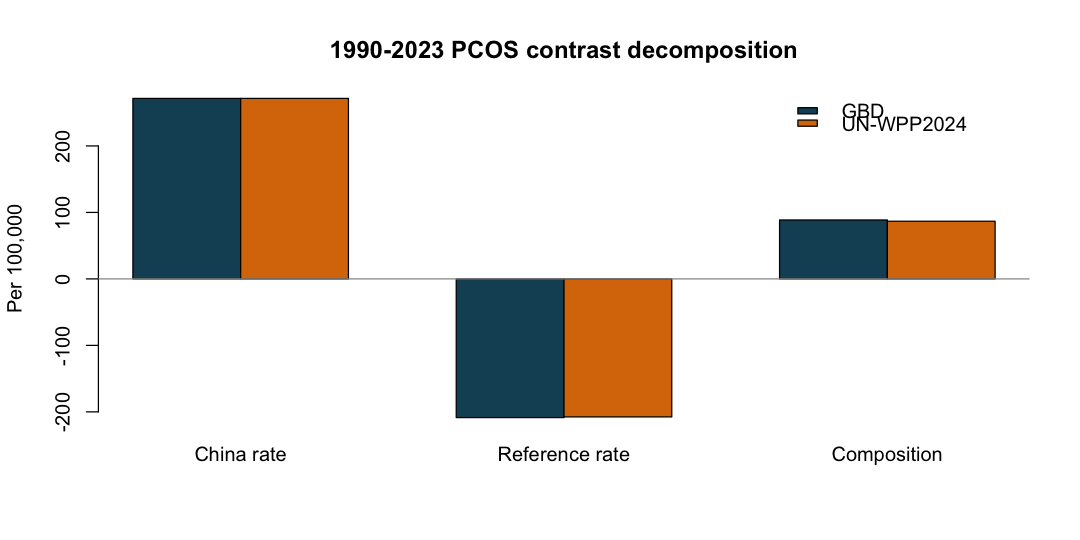

In [2]:
d <- pcos_results$symmetric_decomposition_1990_endpoints
z <- d[d$cause=='Polycystic ovarian syndrome' & d$subtype=='Total' & d$end==2023, ]
z
options(repr.plot.width=9,repr.plot.height=4.5)
m <- as.matrix(z[,c('china_rate_effect','reference_rate_effect','reference_country_composition_effect')])
barplot(m,beside=TRUE,names.arg=c('China rate','Reference rate','Composition'),col=c('#154e63','#d97706'),ylab='Per 100,000',main='1990-2023 PCOS contrast decomposition')
abline(h=0,col='gray60')
legend('topright',legend=z$source,fill=c('#154e63','#d97706'),bty='n')